# Week 7 · Session 1 — Exploring existing data cubes
## Same place, same question, three ways of getting a cube

**Geoprocesamiento · Maestría en Geomática · Universidad Nacional de Colombia**

In the lecture we saw that there are many ways of turning satellite images into a data cube, and that they differ in **where the cube lives** (materialised on disk or built on demand) and in **which layer** they work on (storage, catalogue, loading and alignment, processing). Today we stop looking at diagrams and **use** three of them on the same problem:

> **The question.** *What did the vegetation of the Saldaña irrigated rice district (Tolima) look like between July 2021 and June 2022, both as a median NDVI map and as a time series?*

| Route | Tool | Kind of cube | Time today |
|---|---|---|---|
| **A — main route** | `odc-stac` on Microsoft Planetary Computer (Sentinel-2 L2A) | **on demand**: you define the cube view | ≈ 75 min |
| **B — contrast** | Earth System Data Cube (ESDC v3, Zarr) | **materialised**: the cube already exists, you inherit its grid | ≈ 30 min |
| **C — contrast (optional / demo)** | openEO on the Copernicus Data Space Ecosystem | **virtual and remote**: you describe, a provider computes | ≈ 20 min |

The period deliberately crosses **25 January 2022**, the date on which ESA introduced an offset in Sentinel-2 L2A digital numbers. Keep that in mind.

### What "deep understanding" means today
Running `load(...)` and obtaining a pretty map is easy. The aim of this session is different: for every route you will **audit the decisions** that turned images into a cube — grid, CRS, resampling, what happens with two images on the same day, cloud masking, scale and offset — and you will **measure** how much each decision changes the answer. At the end you will fill in an **audit table** and compare the platforms with the criteria of Kopp et al. (2019).

### How this notebook works
* **Markdown cells** explain *what* we do and *why*; **comments** in the code explain *how*.
* 🤔 **Reflect** cells ask you to think before opening a model answer. Write your own answer first — that is where the learning happens.
* 💡 **Clarification** boxes deal with points that commonly cause confusion.
* ✏️ **Your turn** cells are small challenges: you build something new from what you have just learnt. They are part of the deliverable.

### Deliverables
1. The **audit table** (Section 5) for the three routes.
2. The **sensitivity table** of Section 2 with your interpretation.
3. The **rice vs town signatures** of Section 2.6 (figures + your answers), including the ✏️ third cover and threshold rule — you can finish it at home.
4. Your solutions to the other ✏️ cells.
5. A final paragraph: *"If I had to monitor the rice of Saldaña operationally, which route would I use, and which decisions would I want to control myself?"*

> **Session 2** (next class) builds the cube by hand in HDF5. Today's audit will show you why that is worth doing.

## 0 · Setup

| Library | Why we need it |
|---|---|
| `pystac-client`, `planetary-computer` | search the STAC catalogue and sign asset URLs |
| `odc-stac` | build an `xarray` cube from STAC items (the loading code of Open Data Cube, without its database) |
| `xarray`, `dask` | labelled n-dimensional arrays; lazy, chunked computation |
| `s3fs`, `zarr` | read the Earth System Data Cube directly from cloud object storage |
| `openeo` | client for the openEO API (Route C only) |
| `rasterio` | read the GeoTIFF that openEO returns (installed with `odc-stac`) |

Uncomment the next cell if you are on Google Colab or in a fresh environment.

In [3]:
import time          # measures how long each step takes (e.g. loading the cube)
import warnings      # lets us silence warnings that are expected and harmless

import numpy as np                 # n-dimensional arrays and fast numerical operations
import pandas as pd                # tables (DataFrames) and time series with dates as index
import xarray as xr                # labelled n-dimensional arrays: the data model of our cube (time, y, x, band)
import matplotlib.pyplot as plt    # plots: maps, time series, histograms

import pystac_client               # searches a STAC catalogue by area, dates and properties
import planetary_computer          # signs Planetary Computer asset URLs so that the files can be read
import odc.stac                    # turns STAC items into an xarray cube (Open Data Cube loading, no database)

# --- Session settings ---------------------------------------------------------
# Medians of pixels that are entirely cloud-masked (all NaN) trigger a RuntimeWarning.
# This is expected in a cloudy area, so we hide that warning to keep the output readable.
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Default style for every figure: resolution (dots per inch) and a light background grid
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Print the versions in use: results can change between versions, so record them for reproducibility
print("xarray", xr.__version__,
      "| odc-stac", getattr(odc.stac, "__version__", "?"),   # getattr avoids an error if the version is not exposed
      "| numpy", np.__version__)

xarray 2026.7.0 | odc-stac 0.5.3 | numpy 1.26.4


### 0.1 The area and the period (✏️ you will change these later)

A 3.6 × 3.6 km window on the irrigated plain east of the town of Saldaña. Small on purpose: every load must take seconds or a few minutes, not hours. The window is defined as a longitude/latitude bounding box because that is what STAC searches use; the **cube grid** (CRS and pixel size) is a separate decision that we take later.

> 💡 **Clarification — 0.0163° ≈ 1.8 km.** One degree of latitude is ≈ 110.6 km, so 1.8 km ≈ 0.0163°. Near the equator one degree of longitude is almost the same length ($\cos 3.9° = 0.998$); at 60° latitude it would be half as long, and a square in degrees would be a rectangle in metres.

In [4]:
AOI_NAME = "Saldaña irrigated rice district (Tolima, Colombia)"
CENTRE_LAT, CENTRE_LON = 3.915, -74.985        # degrees, WGS 84
HALF_SIZE_DEG = 0.0163                         # ≈ 1.8 km  -> a 3.6 km window
BBOX = [CENTRE_LON - HALF_SIZE_DEG, CENTRE_LAT - HALF_SIZE_DEG,      # [west, south,
        CENTRE_LON + HALF_SIZE_DEG, CENTRE_LAT + HALF_SIZE_DEG]      #  east, north]
PERIOD = "2021-07-01/2022-06-30"               # crosses 25 January 2022 on purpose
OFFSET_DATE = pd.Timestamp("2022-01-25")       # first Sentinel-2 L2A products with baseline 04.00
CRS = "EPSG:32618"                             # WGS 84 / UTM 18N: floor((-75 + 180) / 6) + 1 = 18
print(AOI_NAME, "| bbox:", np.round(BBOX, 4), "| period:", PERIOD)

Saldaña irrigated rice district (Tolima, Colombia) | bbox: [-75.0013   3.8987 -74.9687   3.9313] | period: 2021-07-01/2022-06-30


## 1 · Route A, step 1 — What does the catalogue give us?

Before any cube exists we have an **image collection**: a list of STAC items. Each item is one Sentinel-2 granule (one MGRS tile of 110 × 110 km on one date) with metadata and links (*assets*) to Cloud-Optimised GeoTIFFs.

We open Planetary Computer with `modifier=planetary_computer.sign_inplace`: every asset URL receives a short-lived access token, so that the files on Azure Blob Storage can be read.

> 📚 **Background — the services and formats we use in Route A**
>
> **Microsoft Planetary Computer** is a free platform run by Microsoft that stores a very large catalogue of Earth-observation and environmental data in its cloud (Azure): Sentinel-1 and Sentinel-2, Landsat, MODIS, elevation models, climate reanalyses and more. The data themselves are public (they come from ESA, NASA, USGS…); what Planetary Computer adds is that they are stored **in cloud-friendly formats** and can be **searched** with a standard catalogue, so you can use them **without downloading whole files**. It offers three things we need today:
> 1. **Storage** — the images are kept as *Cloud-Optimised GeoTIFFs* (see below) on Azure Blob Storage.
> 2. **A STAC catalogue** — the address `https://planetarycomputer.microsoft.com/api/stac/v1` in the next cell.
> 3. **URL signing** — the files are free, but each link needs a short-lived access token. The `planetary-computer` Python package adds it for you (`modifier=planetary_computer.sign_inplace`). No account is needed.
>
> In the four layers of a cube system (lecture), Planetary Computer covers **storage** and **catalogue**; it does **not** build the cube. We do that on our own computer with `odc-stac` (Section 2). *Analogy:* Planetary Computer is the library — it keeps the books and the card index — and we assemble the cube ourselves.
>
> **STAC** (*SpatioTemporal Asset Catalog*) is an open standard for describing geospatial data so that any program can search them in the same way. Its vocabulary:
> * a **Catalog / API** is the searchable service;
> * a **Collection** groups data of the same kind (here `sentinel-2-l2a`);
> * an **Item** is one acquisition over one area (one Sentinel-2 *granule*) with its metadata: date, footprint, cloud cover, processing baseline…;
> * an **Asset** is one file of that item (one band, the cloud mask, a thumbnail), reachable through a URL.
>
> **COG** (*Cloud-Optimised GeoTIFF*) is an ordinary GeoTIFF organised internally in **tiles**, with an index at the beginning of the file. A program can read the index first and then download **only the tiles that cover your area** (with HTTP *range requests*). This is why we can extract our 3.6 km window from a 100 MB band in a fraction of a second.
>
> *Similar services:* **Earth Search** (Element 84, on Amazon Web Services) offers almost the same collections through STAC; the **Copernicus Data Space Ecosystem** (European Union) is the official source of Sentinel data and the openEO provider we use in Route C.

In [5]:
catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)
search = catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime=PERIOD,
                        query={"eo:cloud_cover": {"lt": 80}})   # whole-tile cloud cover, a coarse pre-filter
items = list(search.item_collection())

# One row per item: the metadata we will need to audit the cube
items_df = pd.DataFrame([{
    "id": it.id,
    "time": pd.Timestamp(it.datetime).tz_convert(None),         # UTC, without time-zone label
    "tile": it.properties.get("s2:mgrs_tile"),
    "baseline": it.properties.get("s2:processing_baseline"),
    "platform": it.properties.get("platform"),
    "cloud": it.properties.get("eo:cloud_cover")} for it in items])
items_df = items_df.sort_values(["time", "id"]).reset_index(drop=True)
items_df["date"] = items_df["time"].dt.floor("D")

print(f"{len(items)} items")
print("Items per MGRS tile:", items_df["tile"].value_counts().to_dict())
print("Processing baselines:", items_df["baseline"].value_counts().sort_index().to_dict())
dup = items_df.groupby("date").size()
print(f"Dates with more than one item: {(dup > 1).sum()} of {len(dup)}")
items_df.head()

97 items
Items per MGRS tile: {'18NVK': 50, '18NWK': 47}
Processing baselines: {'03.00': 55, '04.00': 31, '05.10': 11}
Dates with more than one item: 37 of 45


,id,time,tile,baseline,platform,cloud,date
0,S2A_MSIL2A_20210702T152641_R025_T18NVK_2021070...,2021-07-02 15:26:41.024,18NVK,03.00,Sentinel-2A,31.001236,2021-07-02
1,S2A_MSIL2A_20210702T152641_R025_T18NWK_2021070...,2021-07-02 15:26:41.024,18NWK,03.00,Sentinel-2A,51.933531,2021-07-02
2,S2B_MSIL2A_20210707T152639_R025_T18NVK_2021070...,2021-07-07 15:26:39.024,18NVK,03.00,Sentinel-2B,36.404365,2021-07-07
3,S2B_MSIL2A_20210707T152639_R025_T18NWK_2021070...,2021-07-07 15:26:39.024,18NWK,03.00,Sentinel-2B,48.498698,2021-07-07
4,S2A_MSIL2A_20210712T152641_R025_T18NVK_2021071...,2021-07-12 15:26:41.024,18NVK,03.00,Sentinel-2A,57.163245,2021-07-12


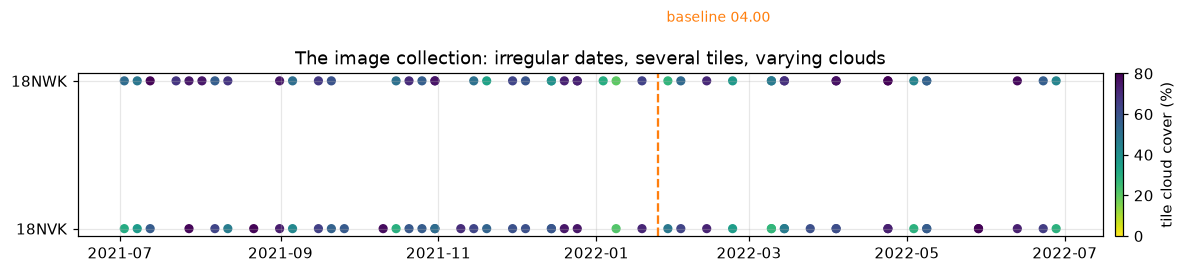

In [6]:
# Acquisition timeline: one dot per item, colour = tile cloud cover, one row per MGRS tile
fig, ax = plt.subplots(figsize=(12, 2.8))
tiles = sorted(items_df["tile"].dropna().unique())
for k, t in enumerate(tiles):
    sub = items_df[items_df["tile"] == t]
    sc = ax.scatter(sub["time"], np.full(len(sub), k), c=sub["cloud"], cmap="viridis_r", vmin=0, vmax=80, s=25)
ax.set_yticks(range(len(tiles)), tiles)
ax.axvline(OFFSET_DATE, color="tab:orange", ls="--")
ax.text(OFFSET_DATE, len(tiles) - 0.6, "  baseline 04.00", color="tab:orange", fontsize=9)
plt.colorbar(sc, ax=ax, label="tile cloud cover (%)", pad=0.01)
ax.set_title("The image collection: irregular dates, several tiles, varying clouds")
plt.tight_layout(); plt.show()

> 📚 **Background — reading the table above**
>
> * **Sentinel-2 L2A**: Sentinel-2 is a pair of ESA satellites (2A, 2B; 2C replaced 2A in 2025) carrying a 13-band multispectral camera. **Level-2A** products give *bottom-of-atmosphere surface reflectance* — the atmosphere has been corrected — plus a pixel classification (the SCL, Section 2.4).
> * **`id`**: the unique name of the item. It encodes the satellite (`S2A`/`S2B`), the product (`MSIL2A`), the acquisition time, the relative orbit (`R025`) and the tile (`T18NVK`).
> * **`tile`** (**MGRS tile**): Sentinel-2 images are cut into squares of about 110 × 110 km on the *Military Grid Reference System*. `18NVK` means UTM zone **18**, latitude band **N**, square **VK**. Neighbouring tiles overlap by about 10 km.
> * **`baseline`** (**processing baseline**): the version of ESA's processing software used to produce the item. Since baseline **04.00** (25 January 2022) the stored numbers include an offset: reflectance = DN / 10 000 − 0.1. Before, reflectance = DN / 10 000.
> * **`cloud`** (`eo:cloud_cover`): the percentage of the **whole tile** covered by clouds — not of our small window. That is why we use it only as a coarse filter (< 80 %) and decide later, pixel by pixel, with the SCL.
> * **DN** (*digital number*): the integer actually stored in the file. It must be converted to reflectance with a scale (and, from 2022, an offset).

> 💡 **Clarification — why several tiles?** MGRS tiles overlap by about 10 km. If the window falls in an overlap, the **same acquisition** is delivered twice, once per tile. The pixels are the same photons, processed twice. A cube with one layer per *item* would count that date twice.

🤔 **Reflect — You see items with baseline 03.xx before January 2022 and 04.xx/05.xx afterwards. Why is this a problem for a cube, if all of them are 'Sentinel-2 L2A'?**

<details><summary>Show a model answer (try first!)</summary>

Because the *meaning of the stored integers* changes. Before baseline 04.00, reflectance $\rho = DN/10000$; from 04.00 onwards $\rho = DN/10000 - 0.1$. A cube that stacks the integers without reading the baseline mixes two different encodings on one time axis. The collection name is the same; the radiometric convention is not. This is exactly the 'consistency' problem of the lecture: a collection is not yet a cube.

</details>

## ✏️ Your turn — explore another rice area

Copy the cell that defines `BBOX` and the search cell below, and run them for **another rice area** — for example the **Meseta de Ibagué** (around 4.40° N, 75.05° W; check on a map and adjust) or an area you know.

1. How many items, tiles and same-day duplicates do you get?
2. Is the area inside one tile, or in an overlap? How can you tell from the table?
3. *Predict* (write it down before checking): would the number of layers in a cube with one layer per item be larger or smaller than the number of distinct dates? By how much?

In [7]:
#  Your code here: a second search for another area (use new variable names, e.g. BBOX_2, items_2)

## 2 · Route A, step 2 — Turning items into a cube with `odc-stac`

`odc.stac.load` is the loading engine of Open Data Cube, made to work directly with STAC items (the STAC catalogue plays the role that the PostgreSQL index plays in a full ODC installation). Its arguments **are the cube view** of Appel & Pebesma (2019):

| Argument | Cube-view decision |
|---|---|
| `bbox` / `geopolygon` | extent |
| `crs` | coordinate reference system of the grid |
| `resolution` | pixel size |
| `resampling` | how source pixels become grid pixels (per band) |
| `groupby` | which items are fused into **one** time layer (`"time"`, `"solar_day"`, `"id"` or a property) |
| `chunks` | if given, the result is a lazy **dask** array (nothing is read yet) |

### 2.1 What happens if we do not decide? (lazy, nothing is downloaded)
First we let the tool decide everything except the bands and the area. With `chunks={}` the call returns immediately: it only reads metadata and builds a **lazy** cube, so we can inspect the decisions it took *before* reading any pixel.

> 📚 **Background — the Python tools that build and hold the cube**
>
> * **`odc-stac`** is the loading engine of **Open Data Cube** packaged as a small library. It takes STAC items and returns an `xarray` cube on the grid you ask for: it reads only the needed parts of each COG, reprojects/resamples them and stacks them in time. In a full Open Data Cube installation a PostgreSQL database indexes the scenes; here the **STAC catalogue plays the role of that index**.
> * **`xarray`** gives us the data model of the cube: arrays with **named dimensions** (`time`, `y`, `x`) and **coordinates** (dates, metres), plus attributes. Instead of remembering "axis 0 is time", you write `cube.sel(time="2022-03")` or `cube.median(dim="time")`.
> * **`dask`** makes arrays **lazy** and **chunked**: an operation first builds a plan (a *task graph*) and only runs when you ask for the result (`.compute()`, `.load()`, a plot). The pieces it works on are *chunks*, the same idea as HDF5 chunks in the lecture.
> * A **Dataset** (`xarray.Dataset`) is a collection of variables that share dimensions — here `B04`, `B08` and `SCL`; a **DataArray** is one of them.

In [ ]:
lazy_default = odc.stac.load(items, bands=["B04", "B08", "SCL"], bbox=BBOX, chunks={})

gb = lazy_default.odc.geobox                       # the grid odc-stac chose for us
print("CRS chosen        :", getattr(gb.crs, "epsg", None) and f"EPSG:{gb.crs.epsg}" or str(gb.crs)[:80])
print("Resolution chosen :", gb.resolution)
print("Shape (y, x)      :", gb.shape)
print("Time layers       :", lazy_default.sizes["time"], "for", len(items), "items")
print("Data types        :", {v: str(lazy_default[v].dtype) for v in lazy_default.data_vars})
print("Attributes of B04 :", dict(lazy_default["B04"].attrs))
lazy_default

🤔 **Reflect — Look at the output. Which decisions did odc-stac take for you, and how could you have found out without this cell?**

<details><summary>Show a model answer (try first!)</summary>

It chose a CRS (normally the native CRS of the items, here UTM 18N), a resolution (from the band metadata), a pixel-grid anchor, a grouping rule (`groupby="time"`: items with *exactly* the same timestamp become one layer), a resampling method (nearest neighbour by default) and the data type (the native `uint16` digital numbers with `nodata = 0`). **No scale or offset was applied**: the values are integers, not reflectance. You could only know this by reading the documentation or inspecting the result — which is precisely why defaults are dangerous in a cube that will be used for science.

</details>

> 💡 **Clarification — "lazy".** `lazy_default` looks like a full cube, but its arrays are dask *task graphs*: recipes that say which bytes of which COG to read and how to warp them. Data are read only when you call `.compute()`, `.load()`, plot, or save. This is the "virtual cube" of the lecture, living in your Python session.

### 2.2 The controlled load: we take the decisions
Now we load the cube that we will actually use, with **explicit** decisions:

* `crs="EPSG:32618"`, `resolution=10`: the native grid of the 10 m bands, so red and NIR are **not resampled**.
* `resampling={"SCL": "nearest"}`: SCL is a **categorical** layer at 20 m; nearest keeps real classes (averaging class codes would invent classes).
* `groupby="id"`: **one layer per item**, no fusing yet. We want to apply our *own* duplicate rule later and measure its effect.

The download is small (only the bytes of our window inside each COG), but there are ~100–200 items: expect one to a few minutes.

In [8]:
t0 = time.perf_counter()
cube = odc.stac.load(items, bands=["B04", "B08", "SCL"], bbox=BBOX,
                     crs=CRS, resolution=10,
                     resampling={"B04": "nearest", "B08": "nearest", "SCL": "nearest"},
                     groupby="id",                         # one layer per item: no fusing yet
                     chunks={"x": 512, "y": 512})          # lazy, read in blocks
cube = cube.compute()                                      # now the pixels are read
print(f"Loaded {cube.sizes} in {time.perf_counter() - t0:.0f} s, "
      f"{sum(v.nbytes for v in cube.data_vars.values()) / 1e6:.0f} MB in memory")

# Quality check: a layer with no valid digital number at all means a failed or empty read
has_data = (cube["B04"] > 0).any(dim=["x", "y"]).values
print(f"Layers with data: {has_data.sum()} of {cube.sizes['time']}"
      + ("" if has_data.all() else "   check the empty ones: " + str(cube['time'].values[~has_data])))

C:\Users\FCA-UN-2240386\.conda\envs\geoprocessing\Lib\site-packages\rasterio\warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


Loaded Frozen({'y': 361, 'x': 363, 'time': 97}) in 158 s, 153 MB in memory
Layers with data: 97 of 97


### 2.3 Attaching provenance to every layer
To correct the offset we need the processing baseline **of each layer**. The loaded cube does not carry the STAC metadata, so we must link every layer back to its item. **Do not rely on the order of the layers**: in a test run, the order of `groupby="id"` did *not* match a simple sort of the item table. Instead we match by **acquisition time**, which both sides share. The two tiles of one acquisition have the same time (and, normally, the same baseline), so for the offset that is all we need.

At the end the cell compares our result with the shortcut "offset = −0.1 for every date after 25 January 2022". If they disagree on some layers, the baseline is **not** a pure function of the date (e.g. scenes acquired just before the switch but processed afterwards) — one more reason to read the metadata instead of assuming.

In [9]:
# Match every cube layer to the STAC items by acquisition time (robust: independent of any ordering)
layers = pd.DataFrame({"layer": np.arange(cube.sizes["time"]),
                       "time": pd.to_datetime(cube["time"].values).astype("datetime64[ns]")}).sort_values("time")
per_time = (items_df.dropna(subset=["baseline"])
            .groupby("time")
            .agg(baseline=("baseline", lambda s: ",".join(sorted(set(s.astype(str))))),
                 n_items=("id", "size"))
            .reset_index().sort_values("time"))
per_time["time"] = per_time["time"].astype("datetime64[ns]")   # same time resolution on both sides
matched = pd.merge_asof(layers, per_time, on="time", direction="nearest",
                        tolerance=pd.Timedelta("1s")).sort_values("layer").reset_index(drop=True)
print("Layers matched to a STAC acquisition time:", matched["baseline"].notna().sum(), "of", len(matched))

mixed = matched["baseline"].str.contains(",", na=False)        # two tiles of one time with different baselines?
if mixed.any():
    print(" Same acquisition time, different baselines:", matched.loc[mixed, "time"].dt.date.tolist())

base_num = pd.to_numeric(matched["baseline"].str.split(",").str[-1], errors="coerce").values
offset = np.where(base_num >= 4.0, -0.1, 0.0)                 # BOA_ADD_OFFSET in reflectance units
missing = np.isnan(base_num)
if missing.any():                                             # fallback only where no metadata matched
    print(f" {missing.sum()} layers without baseline: date rule used for them")
    offset[missing] = np.where(matched.loc[missing, "time"] >= OFFSET_DATE, -0.1, 0.0)
cube = cube.assign_coords(offset=("time", offset.astype("float32")))
layer_meta = matched                                          # keep the per-layer metadata as a table

date_rule = np.where(matched["time"] >= OFFSET_DATE, -0.1, 0.0)
print("Layers with offset -0.1:", int((cube["offset"] < 0).sum()), "of", cube.sizes["time"])
print("Layers where the 'date rule' would give a different offset:", int((date_rule != offset).sum()))

Layers matched to a STAC acquisition time: 97 of 97
⚠️ Same acquisition time, different baselines: [datetime.date(2022, 5, 28), datetime.date(2022, 5, 28), datetime.date(2022, 5, 8), datetime.date(2022, 5, 8), datetime.date(2022, 5, 8), datetime.date(2022, 5, 8), datetime.date(2022, 4, 23), datetime.date(2022, 4, 23), datetime.date(2022, 4, 23), datetime.date(2022, 4, 23), datetime.date(2022, 4, 3), datetime.date(2022, 4, 3), datetime.date(2022, 4, 3), datetime.date(2022, 4, 3), datetime.date(2022, 3, 14), datetime.date(2022, 3, 14), datetime.date(2022, 3, 14), datetime.date(2022, 3, 14), datetime.date(2022, 3, 9), datetime.date(2022, 3, 9), datetime.date(2022, 3, 9), datetime.date(2022, 3, 9), datetime.date(2021, 12, 24), datetime.date(2021, 12, 24), datetime.date(2021, 12, 24), datetime.date(2021, 12, 14), datetime.date(2021, 12, 14), datetime.date(2021, 12, 14), datetime.date(2021, 12, 14)]
Layers with offset -0.1: 46 of 97
Layers where the 'date rule' would give a different offset:

### 2.4 The building blocks: reflectance, NDVI, mask, duplicate rule
Four small functions, each one an explicit decision. Read the comments carefully: these lines are what a high-level tool does — or forgets to do — for you.

> 📚 **Background — the Scene Classification Layer (SCL)**
>
> Every Sentinel-2 L2A item includes an **SCL** band at 20 m: a *categorical* map in which each pixel receives one class code from ESA's processor (Sen2Cor). It is an automatic classification, so it **has errors** (bright roofs labelled as cloud, thin clouds missed).
>
> | Code | Class | Code | Class |
> |---|---|---|---|
> | 0 | no data | 6 | **water** ✓ |
> | 1 | saturated or defective | 7 | unclassified |
> | 2 | dark area / topographic shadow | 8 | cloud, medium probability |
> | 3 | cloud shadow | 9 | cloud, high probability |
> | 4 | **vegetation** ✓ | 10 | thin cirrus |
> | 5 | **not vegetated** (bare soil, built-up) ✓ | 11 | snow or ice |
>
> ✓ = the classes we keep as *clear* (`SCL_CLEAR = [4, 5, 6]`). Water stays, because a flooded paddy **is** water.

In [10]:
SCL_CLEAR = [4, 5, 6]          # vegetation, not vegetated, water (flooded paddies ARE water: keep them)


def to_reflectance(dn, offset):
    # DN -> surface reflectance. DN = 0 is 'no data' in Sentinel-2 L2A, so it becomes NaN.
    return (dn.where(dn > 0) * 1e-4 + offset).astype("float32")


def ndvi(red, nir):
    # NDVI = (NIR - red) / (NIR + red), undefined where the denominator is not positive.
    return ((nir - red) / (nir + red)).where((nir + red) > 0)


def clear_mask(scl, classes=SCL_CLEAR):
    # True where the Scene Classification Layer says the pixel is usable.
    return scl.isin(classes)


def fuse_same_day(da):
    # Duplicate rule: one layer per UTC date, taking for each pixel the FIRST valid value
    # (layers are in time/id order). This is what odc-stac does with groupby="solar_day".
    da = da.assign_coords(date=da["time"].dt.floor("D"))
    return da.groupby("date").first().rename({"date": "time"})

🤔 **Reflect — Why do we apply the mask *before* fusing same-day duplicates, and not after?**

<details><summary>Show a model answer (try first!)</summary>

Because the two duplicates may have *different* masks over the same pixel (they were processed separately, sometimes with different baselines). If we mask first, `first()` skips a cloudy value in tile A and takes the clear value of tile B. If we fused first, we might keep the cloudy value of tile A and then throw the pixel away, losing a valid observation. The order of operations is part of the cube view.

</details>

### 2.5 The sensitivity experiment: one decision at a time

Now the core of the session. We compute the same products — the **AOI median NDVI per date** (a time series) and the **median NDVI map of the period** — under different decisions, changing **one decision at a time**, and we compare everything with a **reference** that applies all corrections (`E3`).

| Id | Offset corrected | SCL mask | Same-day fusing | Grid |
|---|---|---|---|---|
| E0 naive | ✗ | ✗ | ✗ | 10 m |
| E1 | ✓ | ✗ | ✗ | 10 m |
| E2 | ✓ | ✓ | ✗ | 10 m |
| **E3 reference** | ✓ | ✓ | ✓ | 10 m |
| E4 | ✓ | ✓ | ✓ | 30 m, *average* of 3 × 3 |
| E5 | ✓ | ✓ | ✓ | 30 m, *nearest* (centre pixel) |
| E6 | ✗ | ✓ | ✓ | 10 m — "masked but offset ignored" (needed for Route C) |

> 💡 **Clarification — coarsening as resampling.** Our 10 m grid is aligned with the Sentinel-2 lattice, so a 30 m pixel contains exactly 3 × 3 pixels: averaging them (`coarsen(...).mean()`) is *average resampling*, and taking the centre pixel is *nearest neighbour*. We average **reflectances**, then compute NDVI — the mean of NDVIs is not the NDVI of the mean reflectances (NDVI is a non-linear ratio).

In [11]:
def run_experiment(apply_offset=True, use_mask=True, fuse=True, res=10, resampling="average", classes=SCL_CLEAR):
    # Returns an NDVI cube (time, y, x) built with the requested decisions.
    off = cube["offset"] if apply_offset else 0.0
    red = to_reflectance(cube["B04"], off)
    nir = to_reflectance(cube["B08"], off)
    if use_mask:                                   # masked pixels become NaN in both bands
        ok = clear_mask(cube["SCL"], classes)
        red, nir = red.where(ok), nir.where(ok)
    if res == 30:
        if resampling == "average":                # mean of the valid 10 m pixels of each 3 x 3 block
            red = red.coarsen(x=3, y=3, boundary="trim").mean()
            nir = nir.coarsen(x=3, y=3, boundary="trim").mean()
        else:                                      # nearest: keep the centre pixel of each block
            red = red.isel(x=slice(1, None, 3), y=slice(1, None, 3))
            nir = nir.isel(x=slice(1, None, 3), y=slice(1, None, 3))
    v = ndvi(red, nir)
    if fuse:
        v = fuse_same_day(v)
    return v


def aoi_series(v, min_valid=0.2):
    # AOI median NDVI per layer, as a pandas Series indexed by date; NaN if < 20 % of pixels valid.
    med = v.median(dim=["x", "y"])
    frac = v.notnull().mean(dim=["x", "y"])
    s = med.where(frac >= min_valid).to_series().dropna()
    s.index = pd.DatetimeIndex(s.index).floor("D")
    return s.groupby(level=0).mean()               # unfused cubes may have two layers per date


EXPERIMENTS = {
    "E0 naive":            dict(apply_offset=False, use_mask=False, fuse=False),
    "E1 +offset":          dict(apply_offset=True,  use_mask=False, fuse=False),
    "E2 +mask":            dict(apply_offset=True,  use_mask=True,  fuse=False),
    "E3 reference":        dict(apply_offset=True,  use_mask=True,  fuse=True),
    "E4 30 m average":     dict(apply_offset=True,  use_mask=True,  fuse=True, res=30, resampling="average"),
    "E5 30 m nearest":     dict(apply_offset=True,  use_mask=True,  fuse=True, res=30, resampling="nearest"),
    "E6 mask, no offset":  dict(apply_offset=False, use_mask=True,  fuse=True),
}
results = {name: run_experiment(**kw) for name, kw in EXPERIMENTS.items()}
series = {name: aoi_series(v) for name, v in results.items()}
maps = {name: v.median(dim="time") for name, v in results.items()}
ref_s, ref_map = series["E3 reference"], maps["E3 reference"]

rows = []
for name, v in results.items():
    s = series[name]
    common = s.index.intersection(ref_s.index)
    rows.append({"experiment": name,
                 "time layers": v.sizes["time"],
                 "median clear obs / pixel": float(v.notnull().sum("time").median()),
                 "period median NDVI (AOI)": float(maps[name].median()),
                 "mean |Δ series| vs E3": float(np.abs(s[common] - ref_s[common]).mean()) if len(common) else np.nan,
                 "mean Δ series after 25-Jan-2022": float((s[common] - ref_s[common])[common >= OFFSET_DATE].mean())
                                                    if len(common) else np.nan})
sensitivity = pd.DataFrame(rows).set_index("experiment").round(3)
sensitivity

,time layers,median clear obs / pixel,period median NDVI (AOI),mean |Δ series| vs E3,mean Δ series after 25-Jan-2022
experiment,,,,,
E0 naive,97,97.0,0.275,0.209,-0.291
E1 +offset,97,97.0,0.361,0.148,-0.098
E2 +mask,97,57.0,0.568,0.022,0.004
E3 reference,45,24.0,0.559,0.000,0.000
E4 30 m average,45,26.0,0.537,0.020,-0.012
E5 30 m nearest,45,24.0,0.558,0.001,0.001
"E6 mask, no offset",45,24.0,0.429,0.090,-0.231


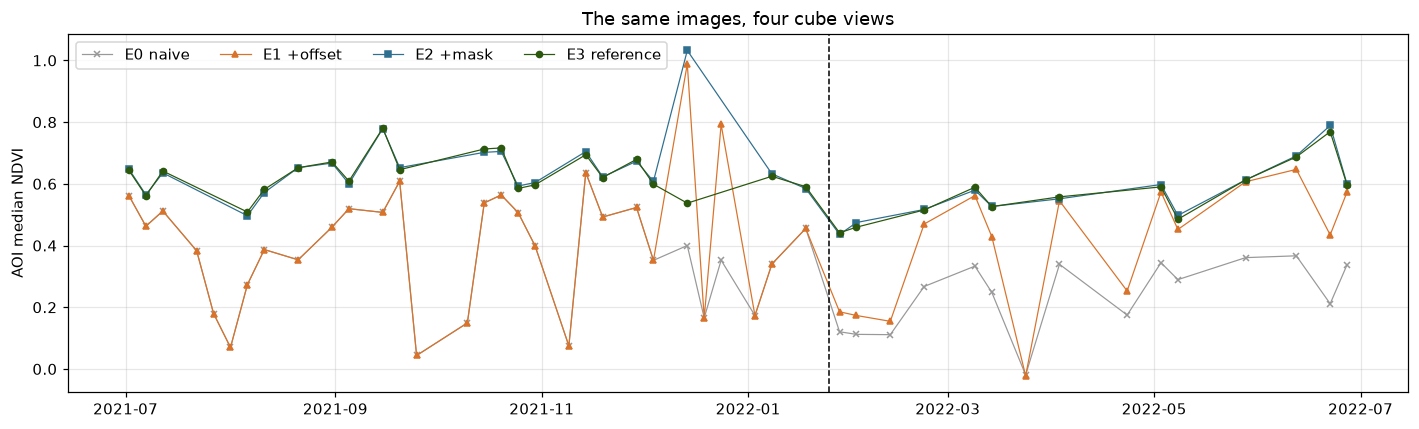

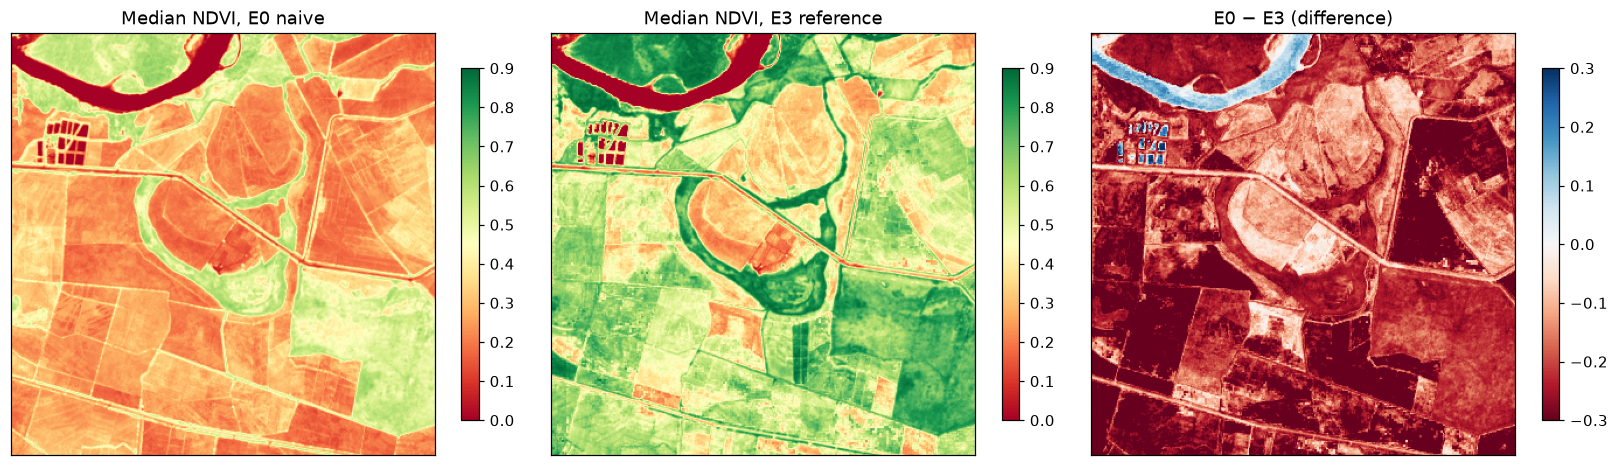

In [12]:
fig, ax = plt.subplots(figsize=(13, 4))
style = {"E0 naive": ("#999999", "x"), "E1 +offset": ("#D9732B", "^"), "E2 +mask": ("#2F6F8F", "s"),
         "E3 reference": ("#2B580C", "o")}
for name, (col, m) in style.items():
    s = series[name]
    ax.plot(s.index, s.values, marker=m, ms=4, lw=0.8, color=col, label=name)
ax.axvline(OFFSET_DATE, color="k", ls="--", lw=1)
ax.set_ylabel("AOI median NDVI"); ax.legend(ncol=4)
ax.set_title("The same images, four cube views")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (name, cmap, lim) in zip(axes, (("E0 naive", "RdYlGn", (0, 0.9)), ("E3 reference", "RdYlGn", (0, 0.9)), (None, "RdBu", (-0.3, 0.3)))):
    arr = maps["E0 naive"] - ref_map if name is None else maps[name]
    im = a.imshow(arr, cmap=cmap, vmin=lim[0], vmax=lim[1])
    a.set_title("E0 − E3 (difference)" if name is None else f"Median NDVI, {name}")
    a.set_xticks([]); a.set_yticks([]); plt.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()

🤔 **Reflect — Which decision changes the answer the most in your table? Is it the one you expected?**

<details><summary>Show a model answer (try first!)</summary>

In most runs the **cloud mask** dominates the time series (unmasked clouds and shadows produce deep drops in NDVI), and the **offset** dominates after 25 January 2022: in E0/E1 vs E3 the series is systematically lower from that date, and the period median map is biased low. Resolution (E4/E5) usually matters least for an AOI median in a landscape of large homogeneous paddies, but it matters at field edges, canals and roads. Your numbers may differ — what matters is that you can **rank** the decisions by their effect, with evidence.

</details>

🤔 **Reflect — E1 corrects the offset and E0 does not, but they look identical before January 2022. Why? And why is the naive NDVI *lower* after that date?**

<details><summary>Show a model answer (try first!)</summary>

Before 25 January 2022 the offset is 0, so both are the same. After that date, ignoring the −0.1 offset adds +0.1 to both red and NIR reflectance: the numerator $\rho_{nir}-\rho_{red}$ is unchanged and the denominator grows by 0.2, so $NDVI' = \frac{\rho_{nir}-\rho_{red}}{\rho_{nir}+\rho_{red}+0.2} < NDVI$. A change-detection method would report a regional 'loss of vegetation' on that date.

</details>

🤔 **Reflect — E3 has fewer time layers than E2, but almost the same series. So does the duplicate rule matter?**

<details><summary>Show a model answer (try first!)</summary>

For an AOI median of the same acquisition, fusing two copies changes little because they contain the same observation. But it matters for **statistics over time**: with duplicates, those dates are counted twice in every temporal median, mean, trend or count of observations (look at the *clear obs / pixel* column). It also matters when the two copies differ (different baselines or masks). The effect is small on one plot and large on a temporal analysis.

</details>

> 💡 **Clarification — "NDVI does not depend on the scale factor".** It is true that NDVI is unchanged if both bands are multiplied by the same factor (10 000 cancels out), which is why many people compute NDVI directly on digital numbers. It is **not** true for an **offset**: adding a constant does not cancel in a ratio. With baseline ≥ 04.00, NDVI on raw digital numbers is wrong.

## ✏️ Your turn — design your own experiment

Choose **one decision we have not tested** and measure its effect with the same table and plot. Some ideas:

* Include SCL class **7 (unclassified)** in `SCL_CLEAR` (use the `classes=` argument). How many observations do you gain? Do they look like clouds?
* Change the duplicate rule: instead of the *first* valid value, take the **mean** of the two copies (hint: replace `.first()` by `.mean()` in a copy of `fuse_same_day`).
* Require a **minimum clear fraction**: drop whole layers where less than 50 % of the AOI is clear before computing the period median map.
* **Verify our coarsening** with a real reload: call `odc.stac.load` with `resolution=30` and `resampling={"B04": "average", "B08": "average", "SCL": "mode"}` for a few items and compare with E4. Are they identical? If not, why?

Write: (1) your hypothesis *before* running, (2) the code, (3) one row added to the sensitivity table, (4) a two-line conclusion.

In [13]:
# ✏️ Your experiment here. Example skeleton:
# my_v = run_experiment(apply_offset=True, use_mask=True, fuse=True, classes=[4, 5, 6, 7])
# my_s = aoi_series(my_v)
# print(float(my_v.median("time").median()), float(np.abs(my_s - ref_s).mean()))

## ✏️ Your turn — a second index for rice

Rice paddies are **flooded** at transplanting. The **LSWI** (Land Surface Water Index) = (NIR − SWIR)/(NIR + SWIR) is sensitive to water; in rice mapping, *LSWI close to or above NDVI* is a classic sign of flooding.

1. Load band **B11** (SWIR 1.6 µm, **20 m**) with `odc.stac.load`. Which `resampling` should you use to bring it to the 10 m grid, and why is this different from SCL?
2. Compute LSWI with **the same decisions as E3** (offset, mask, fusing).
3. Plot NDVI and LSWI for one paddy pixel (choose it on the E3 map) and mark the dates where LSWI ≥ NDVI. Do they make sense as flooding dates?

In [14]:
#  Your code here

## 2.6 · Signatures in time: rice versus town

So far we have treated the AOI as one number per date. But a cube lets us read a **pencil** — the time series of one place — and every land cover has its own **temporal signature**:

* an **irrigated rice paddy** is flooded (water: NDVI close to 0 or negative), turns green very fast (NDVI 0.8 or more), ripens and is harvested, often **twice a year**;
* a **built-up area** (roofs, streets, pavements) has a low, almost **flat** NDVI all year: its materials do not grow.

In this section we compare the two signatures **in time** (NDVI series) and **in the spectrum** (reflectance band by band at three moments of the rice cycle), and we check how the decisions of Section 2.5 — the 2022 offset and the cloud mask — affect each cover **differently**.

The town of Saldaña lies about 1.5 km west of our AOI, so we load a **second, small window** (≈ 600 × 600 m) over the town, with exactly the same decisions as the reference E3. For the spectral signature we also need more bands: blue (B02), green (B03), and the two short-wave infrared bands (B11, B12, at 20 m).

| Band | B02 | B03 | B04 | B08 | B11 | B12 |
|---|---|---|---|---|---|---|
| Colour | blue | green | red | near infrared | SWIR 1 | SWIR 2 |
| ≈ central wavelength (nm) | 490 | 560 | 665 | 842 | 1610 | 2190 |
| Native resolution | 10 m | 10 m | 10 m | 10 m | 20 m | 20 m |

In [15]:
# --- Building blocks reused for both sites -----------------------------------------------
SIG_BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]
WAVELENGTH = {"B02": 490, "B03": 560, "B04": 665, "B08": 842, "B11": 1610, "B12": 2190}   # nm (approximate)
RESAMPLING = {"B02": "nearest", "B03": "nearest", "B04": "nearest", "B08": "nearest",
              "B11": "bilinear", "B12": "bilinear",      # continuous 20 m bands brought to 10 m
              "SCL": "nearest"}                          # categorical: never interpolate class codes


def items_table(items_list):
    # One row per STAC item: time and processing baseline (what we need for the offset).
    return pd.DataFrame([{"id": it.id, "time": pd.Timestamp(it.datetime).tz_convert(None),
                          "baseline": it.properties.get("s2:processing_baseline")} for it in items_list])


def attach_offset(ds, df):
    # Same matching as Section 2.3: link every layer to its STAC acquisition time, then baseline -> offset.
    layers = pd.DataFrame({"layer": np.arange(ds.sizes["time"]),
                           "time": pd.to_datetime(ds["time"].values).astype("datetime64[ns]")}).sort_values("time")
    per_time = (df.dropna(subset=["baseline"]).groupby("time")["baseline"]
                .agg(lambda s: max(s.astype(str))).reset_index())
    per_time["time"] = per_time["time"].astype("datetime64[ns]")
    m = pd.merge_asof(layers, per_time.sort_values("time"), on="time", direction="nearest",
                      tolerance=pd.Timedelta("1s")).sort_values("layer")
    base = pd.to_numeric(m["baseline"], errors="coerce").values
    by_date = np.where(m["time"] >= OFFSET_DATE, -0.1, 0.0)            # fallback only if no metadata
    off = np.where(np.isnan(base), by_date, np.where(base >= 4.0, -0.1, 0.0))
    return ds.assign_coords(offset=("time", off.astype("float32")))


def site_reflectance(ds, bands, apply_offset=True, classes=SCL_CLEAR):
    # Masked, offset-corrected (or not), same-day-fused reflectance for several bands: the E3 decisions.
    off = ds["offset"] if apply_offset else 0.0
    ok = clear_mask(ds["SCL"], classes)
    return xr.Dataset({b: fuse_same_day(to_reflectance(ds[b], off).where(ok)) for b in bands})


SCL_CLASSES = {0: "no data", 1: "saturated/defective", 2: "dark area / shadow", 3: "cloud shadow",
               4: "vegetation", 5: "not vegetated", 6: "water", 7: "unclassified", 8: "cloud medium prob.",
               9: "cloud high prob.", 10: "thin cirrus", 11: "snow/ice"}


def window_series(v, region=None, min_valid=0.5):
    # Median of a window (or of a region inside it) per date; a date is kept only if at least
    # `min_valid` of the region's pixels are clear. Returns a pandas Series indexed by date.
    if region is not None:
        v = v.where(region)
        n_region = int(region.sum())
    else:
        n_region = v.sizes["x"] * v.sizes["y"]
    med = v.median(dim=["x", "y"])
    frac = v.notnull().sum(dim=["x", "y"]) / max(n_region, 1)
    s = med.where(frac >= min_valid).to_series().dropna()
    s.index = pd.DatetimeIndex(s.index).floor("D")
    return s.groupby(level=0).mean()


def site_ndvi(ds, apply_offset=True, classes=SCL_CLEAR):
    r = site_reflectance(ds, ["B04", "B08"], apply_offset, classes)
    return ndvi(r["B04"], r["B08"])

### 2.6.1 The town window
✏️ The centre below is approximate: the RGB map of the next cell lets you **check** that the window really covers streets and roofs. If not, move it and re-run.

In [16]:
TOWN_LAT, TOWN_LON = 3.929, -75.017          # town of Saldaña (approximate: check on the map below)
HALF_TOWN = 0.0027                           # ≈ 300 m  ->  a 600 × 600 m window
BBOX_TOWN = [TOWN_LON - HALF_TOWN, TOWN_LAT - HALF_TOWN, TOWN_LON + HALF_TOWN, TOWN_LAT + HALF_TOWN]

items_town = list(catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX_TOWN, datetime=PERIOD,
                                 query={"eo:cloud_cover": {"lt": 80}}).item_collection())
t0 = time.perf_counter()
town = odc.stac.load(items_town, bands=SIG_BANDS + ["SCL"], bbox=BBOX_TOWN, crs=CRS, resolution=10,
                     resampling=RESAMPLING, groupby="id", chunks={}).compute()
town = attach_offset(town, items_table(items_town))
print(f"town window: {len(items_town)} items, {dict(town.sizes)}, loaded in {time.perf_counter() - t0:.0f} s")

town window: 50 items, {'y': 60, 'x': 61, 'time': 50}, loaded in 149 s


urban pixels selected: 1574 of 3660


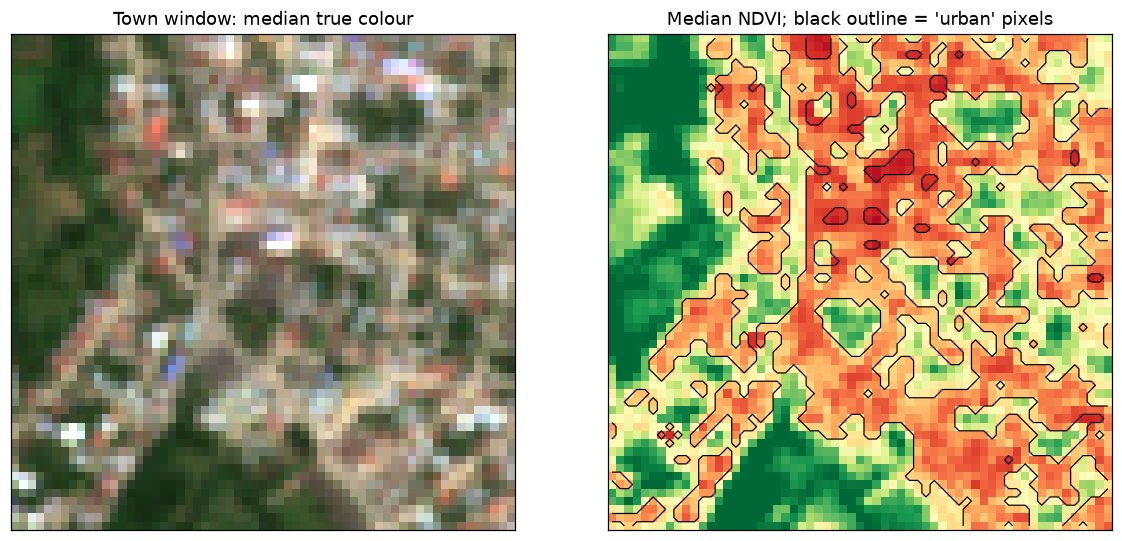

In [17]:
# Which pixels are 'urban'? An objective rule: low and positive median NDVI with enough clear dates.
v_town = site_ndvi(town)
med_town = v_town.median("time")
n_town = v_town.notnull().sum("time")
URBAN = (med_town > 0.0) & (med_town < 0.25) & (n_town >= 10)
print(f"urban pixels selected: {int(URBAN.sum())} of {URBAN.size}")

# Visual check: a cloud-free median true-colour composite with the selected pixels outlined
rgb_t = site_reflectance(town, ["B04", "B03", "B02"]).median("time")
rgb = np.dstack([rgb_t[b].values for b in ("B04", "B03", "B02")])
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(np.clip(rgb / 0.25, 0, 1)); axes[0].set_title("Town window: median true colour")
axes[1].imshow(med_town, cmap="RdYlGn", vmin=-0.1, vmax=0.8)
axes[1].contour(URBAN.values, levels=[0.5], colors="k", linewidths=0.8)
axes[1].set_title("Median NDVI; black outline = 'urban' pixels")
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### 2.6.2 The rice window
We choose a paddy **objectively** from the reference cube E3: among pixels with at least 15 clear dates and a median NDVI above 0.3 (this excludes the river and the ponds, whose large amplitude comes from water), we take the one with the largest NDVI amplitude (90th minus 10th percentile), and a 9 × 9-pixel window (90 × 90 m) around it. The extra bands are loaded lazily for the whole AOI, but only the window is actually read.

rice window centred on row 66, col 92; NDVI amplitude 1.12


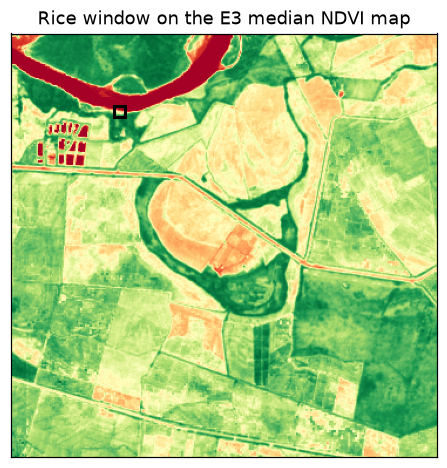

In [18]:
v3 = results["E3 reference"]
q10, q50, q90 = (v3.quantile(q, dim="time") for q in (0.1, 0.5, 0.9))
amp = (q90 - q10).where((v3.notnull().sum("time") >= 15) & (q50 > 0.3))
iy, ix = np.unravel_index(int(np.nanargmax(amp.values)), amp.shape)
iy, ix = int(np.clip(iy, 4, amp.shape[0] - 5)), int(np.clip(ix, 4, amp.shape[1] - 5))
WIN = dict(y=slice(iy - 4, iy + 5), x=slice(ix - 4, ix + 5))
print(f"rice window centred on row {iy}, col {ix}; NDVI amplitude {float(amp[iy, ix]):.2f}")

extra = odc.stac.load(items, bands=["B02", "B03", "B11", "B12"], bbox=BBOX, crs=CRS, resolution=10,
                      resampling=RESAMPLING, groupby="id", chunks={"x": 64, "y": 64})
assert np.array_equal(extra["time"].values, cube["time"].values), "layers differ from the main cube"
extra_win = extra.isel(**WIN).compute()                  # only the window is read
rice = cube[["B04", "B08", "SCL"]].isel(**WIN).copy()   # carries the 'offset' coordinate of Section 2.3
for b in ("B02", "B03", "B11", "B12"):
    rice[b] = (extra_win[b].dims, extra_win[b].values)   # same grid and layers: copy values directly

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(ref_map, cmap="RdYlGn", vmin=-0.1, vmax=0.9)
ax.add_patch(plt.Rectangle((ix - 4.5, iy - 4.5), 9, 9, fill=False, ec="k", lw=2))
ax.set_title("Rice window on the E3 median NDVI map"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

### 2.6.3 Signature in time
Each line is the **median of the window** on each date (a date is kept only if at least half of the window is clear). Solid lines use the reference decisions (E3); dashed lines ignore the 2022 offset (E6).

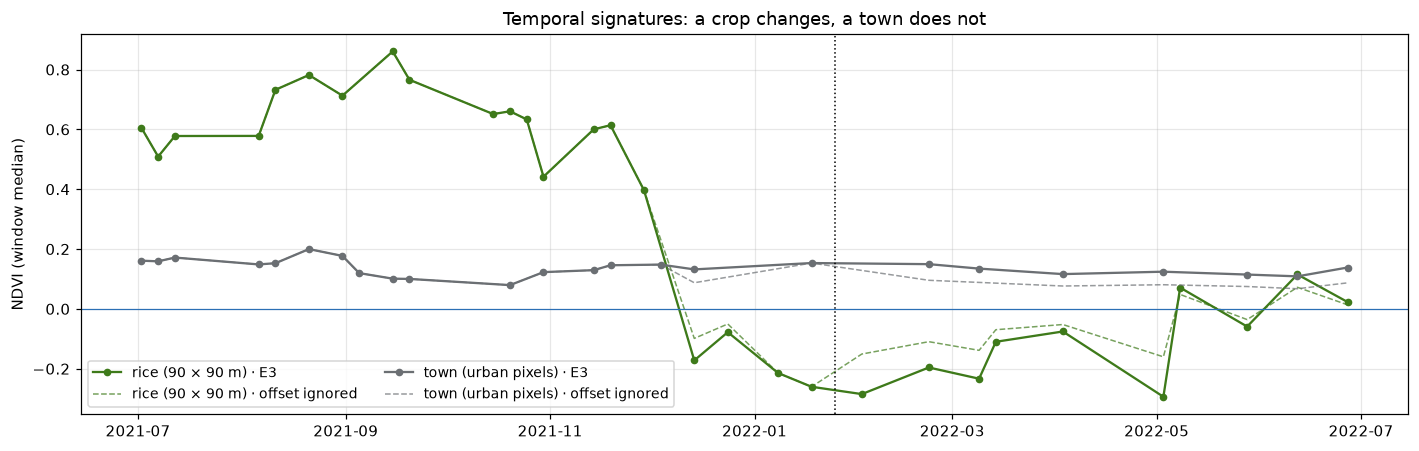

In [19]:
SITES = {"rice (90 × 90 m)": (rice, "#3E7A1A"),
         "town (urban pixels)": (town, "#6B6F73")}


def site_series(ds, name, apply_offset=True):
    region = URBAN if name.startswith("town") else None   # town: only the pixels classified as urban
    return window_series(site_ndvi(ds, apply_offset), region)


fig, ax = plt.subplots(figsize=(13, 4.2))
sig = {}
for name, (ds, col) in SITES.items():
    sig[name] = site_series(ds, name)
    s6 = site_series(ds, name, apply_offset=False)
    ax.plot(sig[name].index, sig[name].values, "o-", ms=4, color=col, label=f"{name} · E3")
    ax.plot(s6.index, s6.values, "--", lw=1, color=col, alpha=0.7, label=f"{name} · offset ignored")
ax.axvline(OFFSET_DATE, color="k", ls=":", lw=1)
ax.axhline(0, color="#2B6FB5", lw=0.8)
ax.set_ylabel("NDVI (window median)"); ax.legend(ncol=2, fontsize=9)
ax.set_title("Temporal signatures: a crop changes, a town does not")
plt.tight_layout(); plt.show()

🤔 **Reflect — Describe the two signatures in words. Which features of the rice curve would let you date a sowing or a harvest, and why can't you do that with the town?**

<details><summary>Show a model answer (try first!)</summary>

The rice curve has **cycles**: very low values (flooded or bare soil), a steep rise (tillering to heading), a plateau and a sharp drop (harvest). The start of the rise dates the sowing/transplanting and the sharp drop dates the harvest; with two cycles you can even tell the two seasons apart. The town curve is **low and flat** (≈ 0.1–0.25), with small fluctuations from illumination, viewing angle, residual clouds or gardens and trees within the pixels: there is no phenology to date. This is why time series, not single images, are the key to telling crops from other covers — on one date in the dry season a harvested paddy and a town can look similar.

</details>

### 2.6.4 Signature in the spectrum, at three moments of the rice cycle
We take three dates from the rice series: the **lowest** NDVI (flooded or bare), the **highest** (full canopy), and one **in between**. For each date we plot the reflectance of every band against its wavelength — the classic *spectral signature* — for both sites (for the town, the closest clear date within ± 10 days).

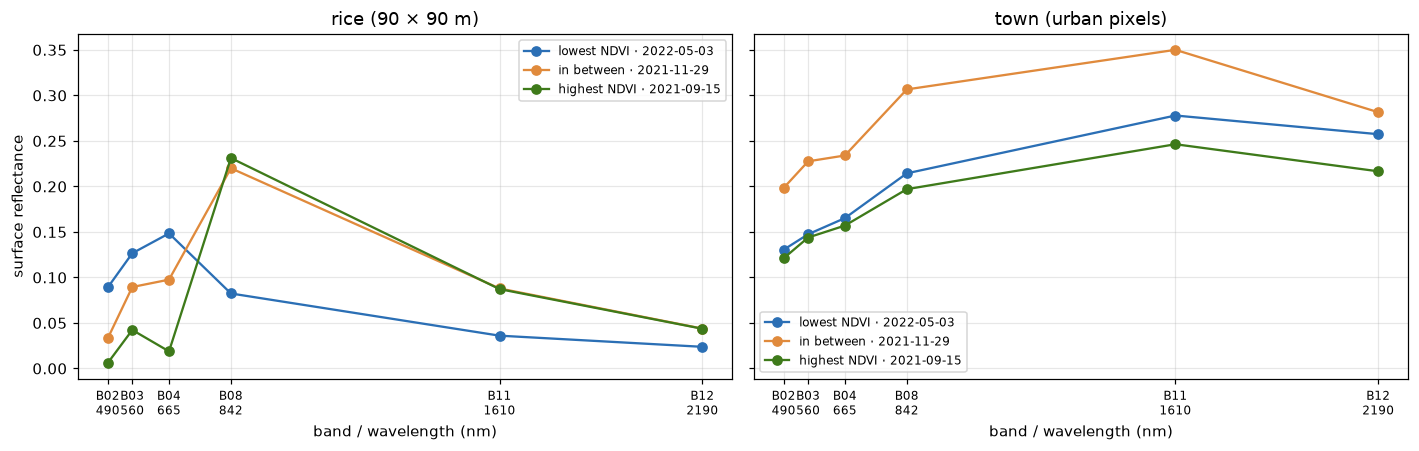

In [20]:
s_r = sig["rice (90 × 90 m)"]
d_low, d_high = s_r.idxmin(), s_r.idxmax()
d_mid = (s_r - (s_r.min() + s_r.max()) / 2).abs().idxmin()
MOMENTS = {"lowest NDVI": (d_low, "#2B6FB5"), "in between": (d_mid, "#E08A3C"), "highest NDVI": (d_high, "#3E7A1A")}

refl = {"rice (90 × 90 m)": site_reflectance(rice, SIG_BANDS).median(["x", "y"]),
        "town (urban pixels)": site_reflectance(town, SIG_BANDS).where(URBAN).median(["x", "y"])}
wl = [WAVELENGTH[b] for b in SIG_BANDS]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (name, r) in zip(axes, refl.items()):
    times = pd.DatetimeIndex(r["time"].values)
    for label, (d, col) in MOMENTS.items():
        k = int(np.abs(times - d).argmin())
        if abs(times[k] - d) > pd.Timedelta(days=10) or np.isnan(r[SIG_BANDS[0]].values[k]):
            continue                                       # no clear observation close to that moment
        ax.plot(wl, [float(r[b].values[k]) for b in SIG_BANDS], "o-", color=col,
                label=f"{label} · {times[k]:%Y-%m-%d}")
    ax.set_xticks(wl, [f"{b}\n{WAVELENGTH[b]}" for b in SIG_BANDS], fontsize=8)
    ax.set_xlabel("band / wavelength (nm)"); ax.set_title(name); ax.legend(fontsize=8)
axes[0].set_ylabel("surface reflectance")
plt.tight_layout(); plt.show()

🤔 **Reflect — Compare the three rice curves with the three town curves. What happens in the near infrared (B08) and in the short-wave infrared (B11, B12), and why?**

<details><summary>Show a model answer (try first!)</summary>

For **rice**, the shape changes completely through the cycle. With full canopy, red is low (chlorophyll absorbs it) and NIR is very high (leaf structure scatters it): the steep "red edge" between B04 and B08 is the signature of green vegetation. When the paddy is flooded, water absorbs NIR and SWIR strongly, so NIR falls to the level of the visible bands and SWIR is very low; with bare soil after harvest, reflectance rises smoothly from blue to SWIR with no red edge. For the **town**, the three curves almost overlap: roofs, asphalt and concrete have a fairly flat or slowly rising spectrum, relatively high in SWIR, and it does not change with the seasons. A crop is a signature that **moves**; a town is a signature that **stays**.

</details>

### 2.6.5 The same decisions, different effects
Two decisions of Section 2.5, measured per site:
* **the 2022 offset:** mean difference between the series that ignores it (E6) and the reference (E3), after 25 January 2022;
* **the cloud mask:** share of the observations that the SCL mask removes, and which SCL classes each site receives.

,median NDVI (E3),mean NDVI error if offset ignored (after 25-Jan-2022),share of observations removed by the mask
site,,,
rice (90 × 90 m),0.419,0.046,0.318
town (urban pixels),0.136,-0.045,0.451


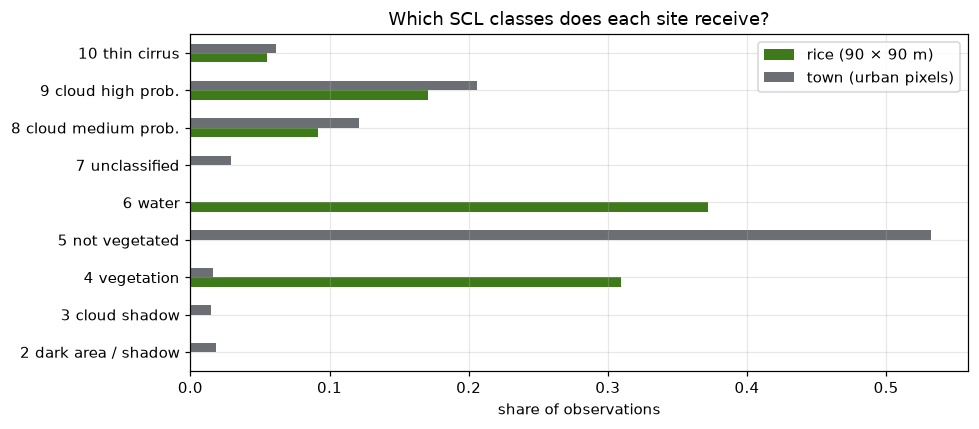

In [21]:
rows = []
scl_freq = {}
for name, (ds, _) in SITES.items():
    s3, s6 = site_series(ds, name), site_series(ds, name, apply_offset=False)
    common = s3.index.intersection(s6.index)
    after = common[common >= OFFSET_DATE]
    scl = ds["SCL"].where(URBAN) if name.startswith("town") else ds["SCL"]
    valid_dn = (ds["B04"] > 0) if not name.startswith("town") else (ds["B04"] > 0) & URBAN
    classes = scl.where(valid_dn).values.ravel()
    classes = classes[~np.isnan(classes)].astype(int)
    scl_freq[name] = pd.Series(classes).value_counts(normalize=True).sort_index()
    rows.append({"site": name,
                 "median NDVI (E3)": float(s3.median()),
                 "mean NDVI error if offset ignored (after 25-Jan-2022)": float((s6[after] - s3[after]).mean()),
                 "share of observations removed by the mask": float(1 - np.isin(classes, SCL_CLEAR).mean())})
display(pd.DataFrame(rows).set_index("site").round(3))

freq = pd.DataFrame(scl_freq).fillna(0)
freq.index = [f"{k} {SCL_CLASSES.get(k, '')}" for k in freq.index]
ax = freq.plot.barh(figsize=(9, 4), color=["#3E7A1A", "#6B6F73"])
ax.set_xlabel("share of observations"); ax.set_title("Which SCL classes does each site receive?")
plt.tight_layout(); plt.show()

🤔 **Reflect — Why is the offset error larger for rice than for the town? Use the formula of Section 2.5.**

<details><summary>Show a model answer (try first!)</summary>

Ignoring the offset gives $NDVI' = \frac{\rho_{nir}-\rho_{red}}{\rho_{nir}+\rho_{red}+0.2}$, so the error is $NDVI - NDVI' = NDVI \cdot \frac{0.2}{\rho_{nir}+\rho_{red}+0.2}$: it is **proportional to NDVI**. Green rice (NDVI ≈ 0.8) loses a lot — a quarter of its value or more; the town (NDVI ≈ 0.15) loses little in absolute terms. Consequence: the offset does not just shift the whole cube, it **compresses the contrast** between vegetation and non-vegetation, and it is largest exactly where the crop signal is strongest.

</details>

🤔 **Reflect — Does the SCL mask treat the two sites equally? What would a false 'cloud' over the town do to its time series, and how could you check it?**

<details><summary>Show a model answer (try first!)</summary>

Usually not. Bright, flat surfaces (metal or white roofs, new concrete) can be classified as cloud or thin cirrus, and dark surfaces (shadows of buildings, wet asphalt) as cloud shadow or dark area: the town tends to lose a larger share of observations, i.e. it gets **false gaps**, and its series is built from fewer dates. Over the paddies, the class that matters most is **water (6)**: if flooded fields were masked, we would lose exactly the flooding phase. To check, open the true-colour image of a date where the town is masked but the rice window is clear (or the image quicklook in the STAC item) and look at whether there really is a cloud. The lecture's warning — "masks are wrong too" — becomes measurable.

</details>

## ✏️ Your turn — a third cover, and a rule to tell them apart

1. **A third signature.** Choose another cover visible in the AOI: the **river**, the **fish ponds** in the north-west, the **riparian forest** along the river, or a **pasture**. Select its pixels with an objective rule (as we did for rice and town), plot its temporal signature next to rice and town, and its spectral signature on the three dates. Describe it in three sentences: what is stable, what changes, and why.
2. **A rule from the signatures.** For every pixel of the AOI and of the town window, compute two features from the E3 cube: the **median NDVI** and the **NDVI amplitude** (90th − 10th percentile). Plot one against the other (a scatter or a 2-D histogram) and colour the pixels of your three or four covers. Propose **thresholds** that separate them (e.g. "amplitude > 0.4 and median > 0.3 → rice"), apply them to the whole AOI as a map, and discuss where they fail.
3. **Your hypothesis about the mask.** Find one date where the town is masked but the rice window is clear. Is it a real cloud? Show the evidence (true-colour image of that date).

*You can finish this part at home: write your conclusions in the cell below and keep the figures for the deliverable.*

In [22]:
#  Your code here

*Your conclusions here.*

## 3 · Route B — A materialised cube: the Earth System Data Cube (ESDC v3)

The ESDC (Mahecha et al., 2020; DeepESDL project) is the opposite philosophy: dozens of Earth-system variables were **already** regridded to one global grid — **0.25° and 8-day steps** — and stored as **Zarr** in public object storage. Nobody asks you which CRS, resolution, mask or aggregation you want: **you inherit them**.

Its vegetation variables (`ndvi`, `kndvi`, `nirv`) were derived from MODIS (product MCD43C4, BRDF-adjusted reflectance at 0.05°), averaged to 8 days, downsampled to 0.25°, gap-filled, and water was masked. Coverage ends in **December 2021**, so it overlaps only the first half of our period.

> 💡 **Clarification — two copies of the same cube.** The ESDC is published **twice with different chunking**: `…-1x720x1440-…` (one chunk = one global map at one date) and `…-256x128x128-…` (one chunk = 256 dates × 128 × 128 cells). Same values, different storage layout — exactly the chunking trade-off of the lecture, at planetary scale.

> 📚 **Background — the services and formats of Route B**
>
> * **Earth System Data Cube (ESDC)**: a ready-made cube produced by the **DeepESDL** project (ESA-funded; Mahecha et al., 2020). Version 3 contains about 40 variables — vegetation indices, gross primary productivity, soil moisture, evaporation, temperature, precipitation… — all regridded to **0.25° (≈ 28 km) and 8-day steps**, from 1979 to 2021 (each variable has its own period).
> * **MODIS MCD43C4**: the source of the ESDC vegetation indices. MODIS is a NASA sensor on the Terra and Aqua satellites (daily, 250 m–1 km); MCD43C4 is a product corrected for the viewing and illumination angles (*BRDF-adjusted*) on a 0.05° global grid.
> * **Zarr**: a format for chunked, compressed n-dimensional arrays — the same ideas as HDF5 — but each chunk is stored as a **separate object** in the cloud, so many users and processes can read different chunks in parallel. Week 8 compares it with HDF5 and NetCDF.
> * **Object storage / S3**: cloud storage where files are "objects" addressed by a URL such as `s3://deep-esdl-public/...`. `s3fs` lets Python read them as if they were files; `anon=True` means anonymous (public) access, no account.
> * **`xr.open_zarr`** opens the cube **lazily**: it reads only the metadata (dimensions, variables, chunk layout). Data are transferred only for the chunks your selection touches — which is why the chunk layout decides the cost of a query.

In [23]:
# Anonymous access to the public DeepESDL bucket (needs s3fs and zarr).
# If this fails, the official route is xcube:
#   from xcube.core.store import new_data_store
#   store = new_data_store("s3", root="deep-esdl-public", storage_options=dict(anon=True))
#   esdc = store.open_data("esdc-8d-0.25deg-256x128x128-3.0.1.zarr")
ESDC_SERIES = "s3://deep-esdl-public/esdc-8d-0.25deg-256x128x128-3.0.1.zarr"   # time-series friendly
ESDC_MAPS = "s3://deep-esdl-public/esdc-8d-0.25deg-1x720x1440-3.0.1.zarr"      # map friendly

esdc = xr.open_zarr(ESDC_SERIES, storage_options={"anon": True})      # lazy: only metadata is read
esdc_maps = xr.open_zarr(ESDC_MAPS, storage_options={"anon": True})
print(f"{len(esdc.data_vars)} variables | dims: {dict(esdc.sizes)}")
print("time:", str(esdc["time"].values[0])[:10], "->", str(esdc["time"].values[-1])[:10])
print("\nndvi attributes:")
for k, v in esdc["ndvi"].attrs.items():
    print(f"  {k}: {str(v)[:120]}")

42 variables | dims: {'time': 1978, 'lat': 720, 'lon': 1440}
time: 1979-01-05 -> 2021-12-31

ndvi attributes:
  acknowledgment: https://lpdaac.usgs.gov/products/mcd43c4v061/
  date_modified: 2022-10-11 23:51:00.603768
  description: MODIS/Terra+Aqua BRDF/Albedo Nadir BRDF-Adjusted Reflectance Daily L3 Global 0.05 Deg CMG and Vegetation Indices
  geospatial_lat_max: 89.875
  geospatial_lat_min: -89.87499999998977
  geospatial_lat_resolution: 0.25
  geospatial_lon_max: 179.87500000008183
  geospatial_lon_min: -179.87499999999997
  geospatial_lon_resolution: 0.25
  license: Terms and conditions of the DeepESDL data distribution
  long_name: Normalized Difference Vegetation Index
  original_add_offset: 0.0
  original_name: NDVI
  original_scale_factor: 1.0
  processing_steps: ['Merging hdf files', 'Computing NDVI, NIRv, and kNDVI', 'resampling by 8-day mean', 'Downsampling to 0.25 deg with mean
  project: DeepESDL
  references: ['https://ntrs.nasa.gov/citations/19740022614', 'https://githu

In [24]:
# How is each copy chunked?  (dask chunk size = stored Zarr chunk size here)
for name, ds in (("series copy", esdc), ("maps copy", esdc_maps)):
    print(f"{name:12s} ndvi dims {esdc['ndvi'].dims}  chunk shape {ds['ndvi'].data.chunksize}")

# Which grid cell contains Saldaña, and how big is it?
lat_name = "lat" if "lat" in esdc.dims else "latitude"
lon_name = "lon" if "lon" in esdc.dims else "longitude"
cell = esdc.sel({lat_name: CENTRE_LAT, lon_name: CENTRE_LON}, method="nearest")
c_lat, c_lon = float(cell[lat_name]), float(cell[lon_name])
side_km = 0.25 * 110.6
print(f"\nNearest cell centre: {c_lat:.3f}, {c_lon:.3f}  (≈ {side_km:.0f} × {side_km:.0f} km)")
print(f"Our 3.6 × 3.6 km window is {100 * 3.6**2 / side_km**2:.1f} % of that cell.")

series copy  ndvi dims ('time', 'lat', 'lon')  chunk shape (256, 128, 128)
maps copy    ndvi dims ('time', 'lat', 'lon')  chunk shape (1, 720, 1440)

Nearest cell centre: 3.875, -74.875  (≈ 28 × 28 km)
Our 3.6 × 3.6 km window is 1.7 % of that cell.


### 3.1 Predict before you click: the cost of reading one pixel time series
We want the NDVI series of that one cell from 2015 to 2021. Use the cost model of the lecture to predict how many **bytes must be decompressed** in each copy (float32 = 4 bytes; a chunk is read entirely):
$$N_{chunks} = \prod_d \left\lceil \frac{q_d}{c_d} \right\rceil,\qquad Bytes = N_{chunks} \times \prod_d c_d \times 4$$

In [25]:
def predicted_mb(ds, var, t0, t1):
    # Uncompressed MB decoded to read one cell's series between dates t0 and t1.
    times = pd.DatetimeIndex(ds["time"].values)
    i0, i1 = times.searchsorted(pd.Timestamp(t0)), times.searchsorted(pd.Timestamp(t1), side="right")
    ct, cy, cx = ds[var].data.chunksize                    # chunk shape (time, lat, lon)
    n_chunks = (i1 - 1) // ct - i0 // ct + 1               # chunks touched along time; 1 along lat and lon
    return n_chunks, n_chunks * ct * cy * cx * 4 / 1e6, i1 - i0

for name, ds in (("series copy", esdc), ("maps copy", esdc_maps)):
    n, mb, steps = predicted_mb(ds, "ndvi", "2015-01-01", "2021-12-31")
    print(f"{name:12s}: {steps} dates -> {n:4d} chunks -> {mb:8.1f} MB to decode "
          f"(useful data: {steps * 4 / 1e3:.1f} kB)")

series copy : 322 dates ->    2 chunks ->     33.6 MB to decode (useful data: 1.3 kB)
maps copy   : 322 dates ->  322 chunks ->   1335.4 MB to decode (useful data: 1.3 kB)


🤔 **Reflect — Which copy would you use for this query, and what would happen in class if 25 people used the other one?**

<details><summary>Show a model answer (try first!)</summary>

The time-series copy: it touches a few chunks; the map copy touches one chunk **per date** (hundreds of chunks of a whole global map each), i.e. gigabytes to obtain a few kilobytes. With 25 people on the same Wi-Fi the map copy would saturate the connection for a very long time. Chunking is not an implementation detail: it decides whether a query is feasible.

</details>

Read in 62.5 s


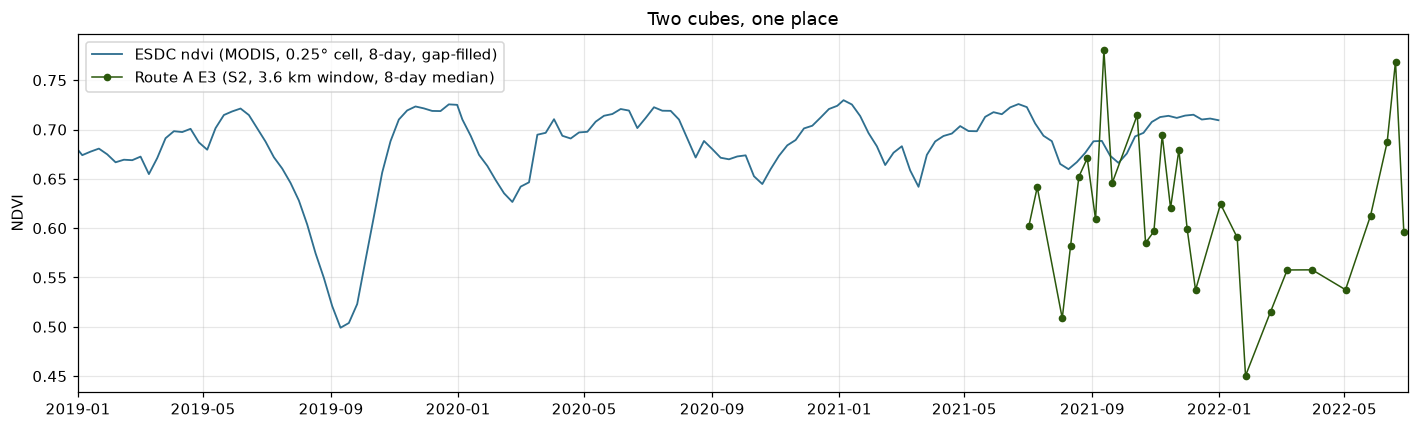

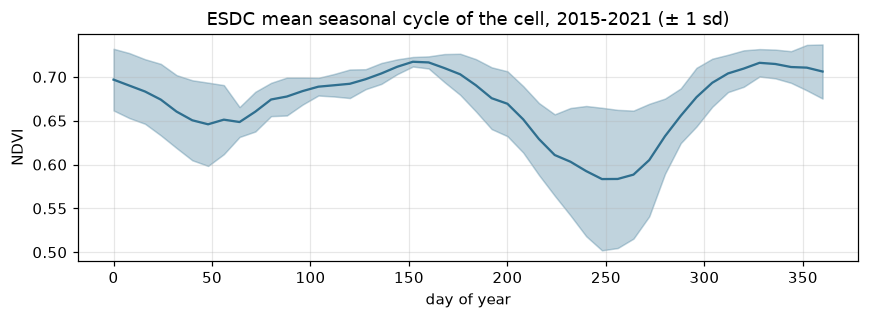

In [26]:
# Read ONLY from the time-series copy (the other one would download gigabytes!)
t0 = time.perf_counter()
cell_ts = esdc[["ndvi", "kndvi"]].sel({lat_name: CENTRE_LAT, lon_name: CENTRE_LON}, method="nearest") \
                                 .sel(time=slice("2015-01-01", "2021-12-31")).load()
print(f"Read in {time.perf_counter() - t0:.1f} s")

esdc_ndvi = cell_ts["ndvi"].to_series()
# Our Route A reference, aggregated to 8-day bins so that both have comparable steps
ours_8d = ref_s.resample("8D").median().dropna()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(esdc_ndvi.index, esdc_ndvi.values, "-", color="#2F6F8F", lw=1.2, label="ESDC ndvi (MODIS, 0.25° cell, 8-day, gap-filled)")
ax.plot(ours_8d.index, ours_8d.values, "o-", color="#2B580C", ms=4, lw=1, label="Route A E3 (S2, 3.6 km window, 8-day median)")
ax.set_xlim(pd.Timestamp("2019-01-01"), pd.Timestamp("2022-07-01"))
ax.set_ylabel("NDVI"); ax.legend(); ax.set_title("Two cubes, one place")
plt.tight_layout(); plt.show()

# What a materialised cube gives you instantly: a mean seasonal cycle (climatology)
clim = esdc_ndvi.groupby(esdc_ndvi.index.dayofyear // 8).agg(["mean", "std"])
plt.figure(figsize=(8, 3))
plt.fill_between(clim.index * 8, clim["mean"] - clim["std"], clim["mean"] + clim["std"], alpha=0.3, color="#2F6F8F")
plt.plot(clim.index * 8, clim["mean"], color="#2F6F8F")
plt.xlabel("day of year"); plt.ylabel("NDVI"); plt.title("ESDC mean seasonal cycle of the cell, 2015-2021 (± 1 sd)")
plt.tight_layout(); plt.show()

🤔 **Reflect — The two series overlap only from July to December 2021, and they do not agree. List at least four reasons, and say which one you think dominates.**

<details><summary>Show a model answer (try first!)</summary>

(1) **Scale:** the ESDC cell is ≈ 28 × 28 km and mixes rice with dry forest, pasture, the river and hills; our window is 1.7 % of it and almost only paddies. (2) **Sensor and processing:** MODIS BRDF-adjusted reflectance vs Sentinel-2 Sen2Cor reflectance, different spectral bands. (3) **Temporal processing:** the ESDC is gap-filled and averaged to 8 days; ours has real gaps and a median of a few observations. (4) **Masking:** water was masked in the ESDC; clouds are handled differently. (5) **Resampling chain:** 0.05° → 0.25° averaging. Scale usually dominates: the ESDC answers questions about *regions*, not *fields*.

</details>

> 💡 **Clarification — "worse" or "different"?** The ESDC is not a worse cube; it was designed for **another question** (global, multi-variable, multi-decadal Earth-system dynamics). Asking it about one paddy is like asking a climate model about one garden. Choosing a cube means matching its grid to the scale of your question.

## ✏️ Your turn — ask the ESDC a question it *can* answer

Formulate a question at the right scale for the ESDC and answer it. Before reading any data, **predict the cost** with `predicted_mb` and justify the chunk copy you use. Ideas:

* Was 2021 a normal year for vegetation in the Saldaña cell? Compute the **anomaly** of 2021 with respect to the 2001–2020 climatology of `ndvi`.
* How does the vegetation cycle of the cell relate to rainfall? Read `precipitation_era5` for the same cell and plot both cycles (mean per 8-day step). Is there a lag?
* Read a small **regional box** (e.g. 3–5° N, 76–74° W, the Magdalena valley around Saldaña) for **one date** of `gross_primary_productivity`: which copy is cheaper now, and why?

In [27]:
#  Your code here

## 4 · Route C (optional / demo) — A virtual, remote cube: openEO

openEO is not a cube or a format but an **API standard**. You build a **process graph** — load a collection, filter, compute, reduce — on a *virtual* cube, and a provider runs it **where the data are**; you download only the result. The same script can run on any provider that implements the standard.

We use the **Copernicus Data Space Ecosystem** (free account needed: register at dataspace.copernicus.eu *before* class). If you do not have an account, read the cells and look at the process graph: your lecturer will show the result.

> 💡 **Clarification — nothing is computed until `download`.** Every line before it only adds nodes to the graph. Print the graph (`to_json()`) and you will see the cube view written as a recipe.

> 📚 **Background — the services of Route C**
>
> * **openEO** is an **open API standard** (a common language between a client and a cloud provider) for processing Earth-observation data. You describe the processing in Python, R or JavaScript; the client turns it into a **process graph** (a JSON recipe); the provider runs it next to the data and you download only the result. Any provider that implements the standard can run the same script.
> * The **Copernicus Data Space Ecosystem (CDSE)** is the European Union's official platform for Copernicus (Sentinel) data. It offers search, download, visualisation and an openEO service at `openeo.dataspace.copernicus.eu`. A **free account** gives a monthly allowance of processing credits.
> * **`authenticate_oidc()`** logs you in with *OpenID Connect*: the client shows a link (and sometimes a code); you open it in the browser, log in with your CDSE account, and the notebook continues. Nothing is stored in the notebook.
> * **`load_collection`, `band`, `mask`, `reduce_dimension`, `download`** are openEO *processes*: each one adds a step to the recipe. Only `download` (or `execute`) sends the recipe to the provider.

In [28]:
RUN_OPENEO = True          #  set to True if you have a Copernicus Data Space account

if RUN_OPENEO:
    import openeo
    con = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()   # opens a browser login
    start, end = PERIOD.split("/")
    s2 = con.load_collection("SENTINEL2_L2A",
                             spatial_extent={"west": BBOX[0], "south": BBOX[1], "east": BBOX[2], "north": BBOX[3]},
                             temporal_extent=[start, str((pd.Timestamp(end) + pd.Timedelta(days=1)).date())],  # end is exclusive
                             bands=["B04", "B08", "SCL"])
    red, nir, scl = s2.band("B04"), s2.band("B08"), s2.band("SCL")
    ndvi_oe = (nir - red) / (nir + red)                       # computed on whatever values the backend delivers
    cloudy = ~((scl == 4) | (scl == 5) | (scl == 6))           # the same clear classes as Route A
    median_oe = ndvi_oe.mask(cloudy).reduce_dimension(dimension="t", reducer="median")
    print(median_oe.to_json()[:3000])                          # the process graph: the cube view as a recipe

Authenticated using refresh token.
{
  "process_graph": {
    "loadcollection1": {
      "process_id": "load_collection",
      "arguments": {
        "bands": [
          "B04",
          "B08",
          "SCL"
        ],
        "id": "SENTINEL2_L2A",
        "spatial_extent": {
          "west": -75.0013,
          "south": 3.8987,
          "east": -74.9687,
          "north": 3.9313000000000002
        },
        "temporal_extent": [
          "2021-07-01",
          "2022-07-01"
        ]
      }
    },
    "reducedimension1": {
      "process_id": "reduce_dimension",
      "arguments": {
        "data": {
          "from_node": "loadcollection1"
        },
        "dimension": "bands",
        "reducer": {
          "process_graph": {
            "arrayelement1": {
              "process_id": "array_element",
              "arguments": {
                "data": {
                  "from_parameter": "data"
                },
                "index": 1
              }
            

Computed remotely and downloaded in 48 s
openEO grid: EPSG:32618 (10.0, 10.0) (361, 363)
openEO                           0.501
Route A E3 (offset corrected)    0.559
Route A E6 (offset ignored)      0.429
dtype: float64


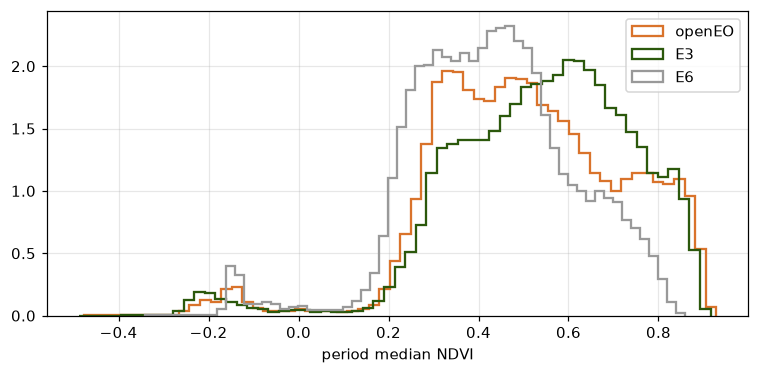

In [29]:
if RUN_OPENEO:
    import rasterio
    t0 = time.perf_counter()
    median_oe.download("openeo_ndvi_median.tif", format="GTiff")   # the provider computes now
    print(f"Computed remotely and downloaded in {time.perf_counter() - t0:.0f} s")
    with rasterio.open("openeo_ndvi_median.tif") as src:
        oe = src.read(1, masked=True).filled(np.nan)
        print("openEO grid:", src.crs, src.res, src.shape)

    comparison = pd.Series({"openEO": np.nanmedian(oe),
                            "Route A E3 (offset corrected)": float(maps["E3 reference"].median()),
                            "Route A E6 (offset ignored)": float(maps["E6 mask, no offset"].median())})
    print(comparison.round(3))
    plt.figure(figsize=(7, 3.5))
    for name, arr, col in (("openEO", oe.ravel(), "#D9732B"), ("E3", maps["E3 reference"].values.ravel(), "#2B580C"),
                           ("E6", maps["E6 mask, no offset"].values.ravel(), "#999999")):
        plt.hist(arr[np.isfinite(arr)], bins=60, histtype="step", lw=1.5, color=col, label=name, density=True)
    plt.xlabel("period median NDVI"); plt.legend(); plt.tight_layout(); plt.show()

🤔 **Reflect — Does the openEO backend correct the 2022 offset? How can you find out *without* reading its source code?**

<details><summary>Show a model answer (try first!)</summary>

Compare its result with the two Route A variants that differ only in the offset (E3 corrected, E6 not). In a test run over Saldaña the period median was **0.50 for openEO, 0.55 for E3 and 0.43 for E6**: *between* the two. A single period median is therefore **not conclusive**, because other decisions also differ between the routes (how the two tiles of a date are fused, how the 20 m SCL is brought to 10 m, which processing version the provider serves). The conclusive test is **date by date**: ask openEO for the AOI median NDVI of every date (e.g. with `aggregate_spatial`) and plot it with E3 and E6. If it follows E3 before 25 January 2022 and drops towards E6 afterwards, the backend does not correct the offset; if it follows E3 throughout, it does (the solutions notebook shows the code). You can also inspect the collection metadata (`con.describe_collection("SENTINEL2_L2A")`) and the provider documentation. This is an empirical audit: you do not trust, you test — and you write the answer in the audit table.

</details>

> 💡 **Clarification — why not compare pixel by pixel?** The openEO result is on the provider's grid (its own extent snapping and pixel alignment), not exactly on ours. Comparing pixel by pixel would require resampling one of them — adding yet another decision. Comparing **distributions** and AOI statistics avoids that.

## ✏️ Your turn — write your own process graph

Modify the openEO graph to answer a different question **without downloading the images**. Options:

* the **number of clear observations** per pixel in the period (hint: a reducer such as `"count"` on the masked NDVI);
* a **monthly** NDVI median cube (hint: `aggregate_temporal_period(period="month", reducer="median")`) and its AOI series compared with Route A;
* the **maximum** NDVI of each rice season.

Print the process graph and identify in it every cube-view decision (extent, period, bands, mask, reducer). Which decisions could you **not** control from the client?

In [30]:
#  Your code here

## 5 · Synthesis — the audit table

✏️ Double-click this cell and fill in the table with what **you** found (not what the documentation promises). For every cell, also note **who took the decision**: *you*, *the tool by default*, or *the cube producer*.

| Decision | Route A · odc-stac | Route B · ESDC | Route C · openEO |
|---|---|---|---|
| Grid: CRS and pixel size | | | |
| Who chose the grid? | | | |
| Resampling of reflectance / of SCL | | | |
| Same-day duplicates | | | |
| Cloud / quality masking | | | |
| Scale factor and 2022 offset | | | |
| Gap filling / temporal aggregation | | | |
| Where the computation ran | | | |
| What was downloaded (≈ MB) | | | |
| Provenance available (item ids, versions) | | | |

### 5.1 Comparing platforms: the criteria of Kopp et al. (2019)
Score each route from 0 to 2 **with one sentence of evidence from today** (a number, an observation, an error you met).

| Criterion | Route A | Route B | Route C |
|---|---|---|---|
| Analysis Ready Data | | | |
| Rich metadata / provenance | | | |
| Interoperability | | | |
| Efficient and scalable access | | | |
| Ease of analysis | | | |

🤔 **Reflect — Looking at your audit table: in which route did *you* take the most decisions, and is that an advantage or a burden?**

<details><summary>Show a model answer (try first!)</summary>

In Route A you took (or could take) almost every decision; in Route B almost none; in Route C some (extent, bands, mask, reducer) but not others (grid alignment, internal resampling, value harmonisation). Control is an advantage when your question is specific (fields, a crop calendar, a known radiometric issue) and a burden when you need speed, scale or many variables. The skill is not to prefer one route, but to **know which decisions each route takes for you** and to check the ones that matter for your question.

</details>

## ✏️ Your turn — final paragraph 

*If I had to monitor the rice of Saldaña operationally (every new image, every season, for years), which route would I use, and which decisions would I want to control myself? What would I need that none of today's routes gave me?*

Write 8–12 lines below, citing evidence from your tables.

*Your answer here.*

---
### Key ideas to take away
1. A cube is always the result of a **cube view** — extent, CRS, resolution, resampling, duplicate rule, masking, radiometric conventions — whether you write it or a tool or a producer decides it.
2. **Defaults are decisions.** `odc.stac.load` returned raw integers with the offset untouched; the ESDC gave us a 28 km cell; openEO hid the grid alignment.
3. The decisions that matter most depend on the question: here, **masking and the 2022 offset** mattered more than resolution for the AOI series.
4. **Chunking decides feasibility**: the same ESDC values cost kilobytes or gigabytes depending on the copy.
5. **Audit empirically**: compare routes, test hypotheses, record the answers. Next session we build a cube where *every* decision is ours and written in the file.

## References
* Kopp, S. et al. (2019). Achieving the full vision of Earth observation data cubes. *Data*, 4(3), 94. https://doi.org/10.3390/data4030094
* Appel, M. & Pebesma, E. (2019). On-demand processing of data cubes from satellite image collections with the gdalcubes library. *Data*, 4(3), 92. https://doi.org/10.3390/data4030092
* Lewis, A. et al. (2017). The Australian Geoscience Data Cube — foundations and lessons learned. *Remote Sensing of Environment*, 202, 276–292. https://doi.org/10.1016/j.rse.2017.03.015
* Mahecha, M. D. et al. (2020). Earth system data cubes unravel global multivariate dynamics. *Earth System Dynamics*, 11, 201–234. https://doi.org/10.5194/esd-11-201-2020
* Montero, D. et al. (2025). Earth System Data Cubes: Avenues for advancing Earth system research. *Environmental Data Science*, 3, e27. https://doi.org/10.1017/eds.2024.22
* Schramm, M. et al. (2021). The openEO API — Harmonising the use of Earth observation cloud services using virtual data cube functionalities. *Remote Sensing*, 13(6), 1125. https://doi.org/10.3390/rs13061125
* Marshall, E. et al. (2025). Cloud-native geospatial data cube workflows with open-source tools. *Journal of Open Source Education*, 8(89), 267. https://doi.org/10.21105/jose.00267
* odc-stac documentation, `odc.stac.load`: https://odc-stac.readthedocs.io/
* DeepESDL — Earth System Data Cube v3 documentation: https://deepesdl.readthedocs.io/en/latest/datasets/ESDC
* openEO Python client documentation: https://open-eo.github.io/openeo-python-client/